In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Project environment ready!")

Project environment ready!


In [2]:
file_path = "../data/raw/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Dataset dimensions:", df.shape)

df.head()

Dataset dimensions: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Total missing values: 136534
Duplicate rows: 5268


In [7]:
cancelled_invoices = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled invoice records:", len(cancelled_invoices))

cancelled_invoices.head()

Cancelled invoice records: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [8]:
negative_quantity = df[df["Quantity"] < 0]

print("Records with negative quantity:", len(negative_quantity))

negative_quantity.head()

Records with negative quantity: 10624


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [9]:
zero_price = df[df["UnitPrice"] == 0]

negative_price = df[df["UnitPrice"] < 0]

print("Zero-price records:", len(zero_price))
print("Negative-price records:", len(negative_price))

Zero-price records: 2515
Negative-price records: 2


In [10]:
print("Total unique customers:", df["CustomerID"].nunique())

print(
    "Unique customers with missing IDs:",
    df["CustomerID"].isnull().sum()
)

Total unique customers: 4372
Unique customers with missing IDs: 135080


In [11]:
# Records that have both cancelled invoices and negative quantities

cancelled_and_negative = df[
    df["InvoiceNo"].astype(str).str.startswith("C") &
    (df["Quantity"] < 0)
]

print(
    "Cancelled invoices with negative quantities:",
    len(cancelled_and_negative)
)

Cancelled invoices with negative quantities: 9288


In [12]:
# Negative quantities without a cancelled invoice number

negative_without_cancellation = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C") &
    (df["Quantity"] < 0)
]

print(
    "Negative quantities without cancellation prefix:",
    len(negative_without_cancellation)
)

Negative quantities without cancellation prefix: 1336


In [13]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


In [14]:
df_clean = df_clean.dropna(subset=["CustomerID"])

print("Shape after removing missing Customer IDs:", df_clean.shape)
print("Missing Customer IDs remaining:", df_clean["CustomerID"].isnull().sum())

Shape after removing missing Customer IDs: (406829, 8)
Missing Customer IDs remaining: 0


In [15]:
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Shape after removing cancelled invoices:", df_clean.shape)

Shape after removing cancelled invoices: (397924, 8)


In [16]:
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

print("Shape after removing invalid quantities and prices:", df_clean.shape)

Shape after removing invalid quantities and prices: (397884, 8)


In [17]:
df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Shape after removing duplicates: (392692, 8)
Remaining duplicate rows: 0


In [18]:
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean[["Quantity", "UnitPrice", "TotalPrice"]].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [19]:
print("========== DATA CLEANING REPORT ==========")

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

print(
    "Records removed:",
    len(df) - len(df_clean)
)

print(
    "Unique customers:",
    df_clean["CustomerID"].nunique()
)

print(
    "Remaining missing values:",
    df_clean.isnull().sum().sum()
)

print(
    "Remaining duplicates:",
    df_clean.duplicated().sum()
)

print("==========================================")

========== DATA CLEANING REPORT ==========
Original records: 541909
Cleaned records: 392692
Records removed: 149217
Unique customers: 4338
Remaining missing values: 0
Remaining duplicates: 0


# 3. Exploratory Business Analysis

In [20]:
# Check the date range of our cleaned dataset

print("First transaction:", df_clean["InvoiceDate"].min())

print("Last transaction:", df_clean["InvoiceDate"].max())

print("Total revenue:", df_clean["TotalPrice"].sum())

print("Average transaction line value:", df_clean["TotalPrice"].mean())

print("Number of unique invoices:", df_clean["InvoiceNo"].nunique())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00
Total revenue: 8887208.894000001
Average transaction line value: 22.631499735161402
Number of unique invoices: 18532


In [21]:
# Calculate total value of each invoice

order_totals = df_clean.groupby("InvoiceNo")["TotalPrice"].sum()

# Calculate Average Order Value

average_order_value = order_totals.mean()

print("Average Order Value:", average_order_value)
print("Highest order value:", order_totals.max())
print("Lowest order value:", order_totals.min())


Average Order Value: 479.56016047917126
Highest order value: 168469.6
Lowest order value: 0.38


In [22]:
# Find the 10 highest-value orders

top_orders = order_totals.sort_values(
    ascending=False
).head(10)

print("Top 10 highest-value orders:")
print(top_orders)

Top 10 highest-value orders:
InvoiceNo
581483    168469.60
541431     77183.60
556444     38970.00
567423     31698.16
556917     22775.93
572209     22206.00
567381     22104.80
563614     21880.44
550461     21535.90
572035     20277.92
Name: TotalPrice, dtype: float64


## 3.1 Monthly Revenue Analysis

In [23]:
# Extract month and year from InvoiceDate

df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

# Calculate monthly revenue

monthly_revenue = df_clean.groupby(
    "YearMonth"
)["TotalPrice"].sum()

print("Monthly Revenue:")
print(monthly_revenue)

Monthly Revenue:
YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: TotalPrice, dtype: float64


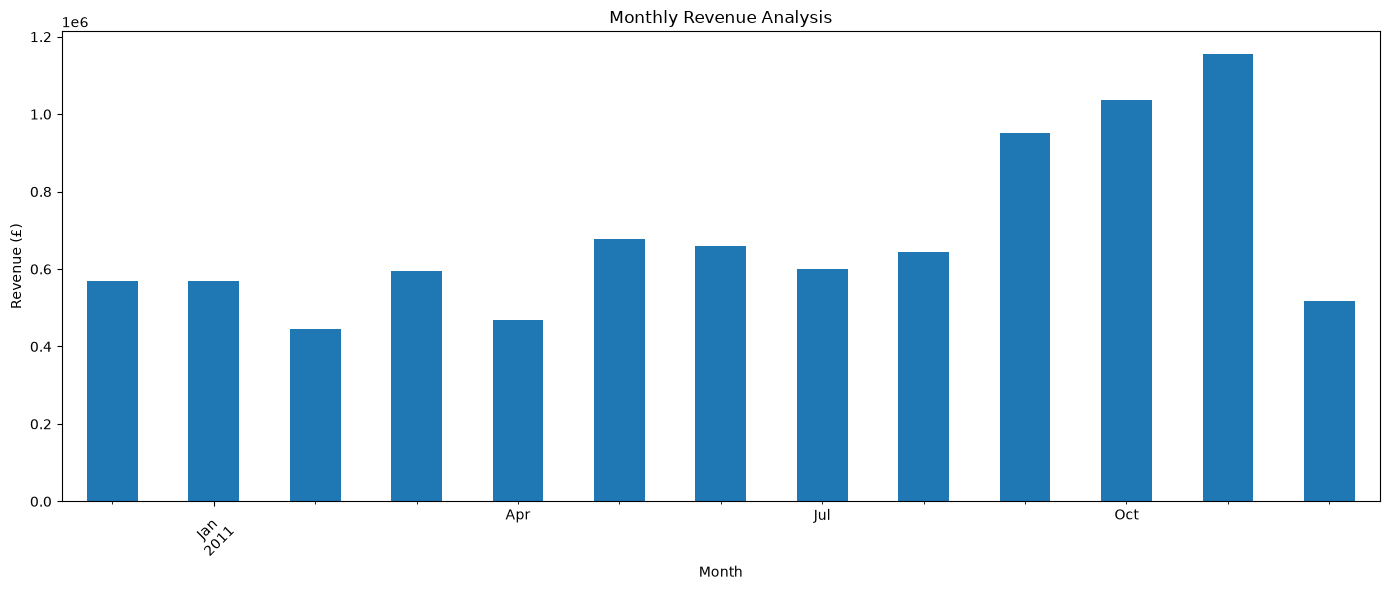

In [24]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [25]:
# Set the reference date
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Group transactions by customer
rfm = df_clean.groupby("CustomerID").agg({

    "InvoiceDate": lambda x: (reference_date - x.max()).days,

    "InvoiceNo": "nunique",

    "TotalPrice": "sum"

})

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

# Display the first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


## 4. RFM Distribution Analysis

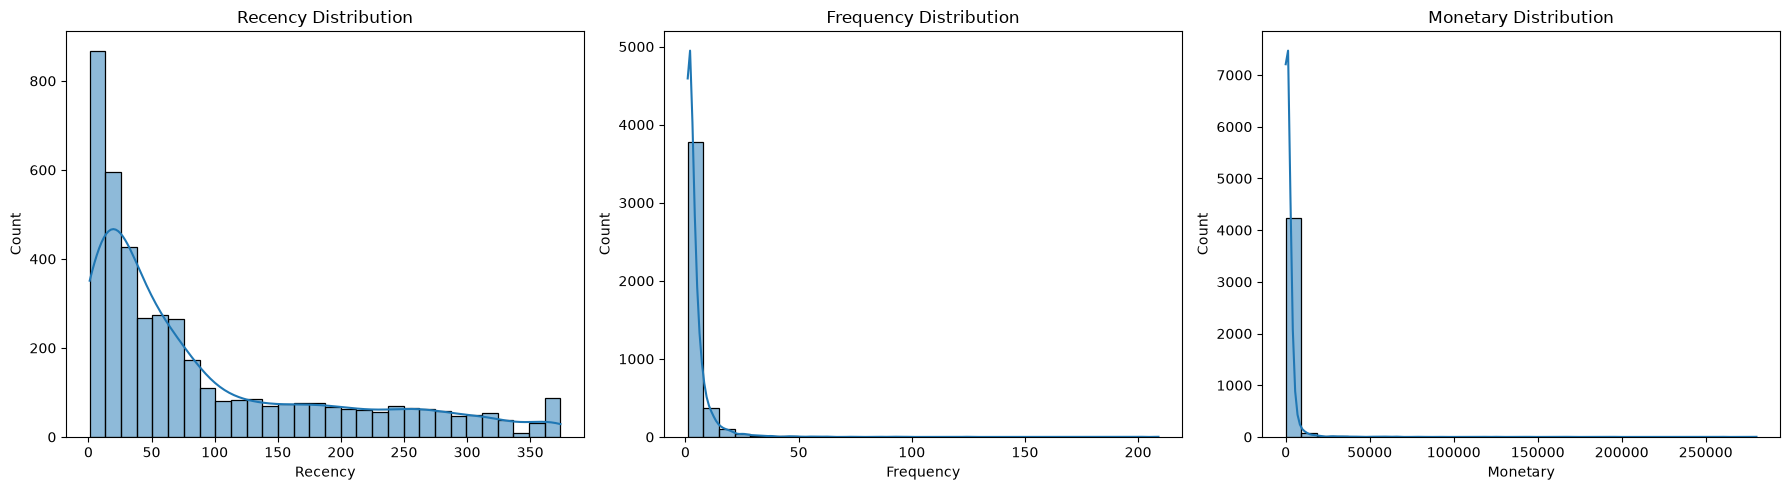

In [26]:
# Create three distribution plots

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
sns.histplot(rfm["Recency"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Recency Distribution")

# Frequency distribution
sns.histplot(rfm["Frequency"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Frequency Distribution")

# Monetary distribution
sns.histplot(rfm["Monetary"], bins=30, kde=True, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [27]:
print("RFM Skewness:")
print(rfm.skew())

RFM Skewness:
Recency       1.246048
Frequency    12.067031
Monetary     19.339368
dtype: float64


In [28]:
# Create a copy of our RFM data

rfm_log = rfm.copy()

# Apply log transformation

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

# Check new skewness

print("Skewness after log transformation:")
print(rfm_log.skew())

Skewness after log transformation:
Recency     -0.379169
Frequency    1.208652
Monetary     0.396599
dtype: float64


In [29]:
from sklearn.preprocessing import StandardScaler

In [30]:
# Initialize the scaler

scaler = StandardScaler()

# Fit and transform our log-transformed data

rfm_scaled_array = scaler.fit_transform(rfm_log)

# Convert the result back into a DataFrame

rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    columns=rfm_log.columns,
    index=rfm_log.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.707716
12347.0,-2.038734,1.074425,1.414903
12348.0,0.373104,0.386304,0.720024
12349.0,-0.623086,-0.955214,0.702287
12350.0,1.424558,-0.955214,-0.614514


In [31]:
print("Mean of scaled features:")
print(rfm_scaled.mean())

print("\nStandard deviation of scaled features:")
print(rfm_scaled.std())

Mean of scaled features:
Recency     -8.025955e-17
Frequency   -8.189750e-18
Monetary    -3.669008e-16
dtype: float64

Standard deviation of scaled features:
Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64


In [32]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [33]:
# Store the inertia values
inertia_values = []

# Test different numbers of clusters
K = range(1, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

print("Inertia values:")
print(inertia_values)

Inertia values:
[13014.000000000002, 6483.589425039298, 4869.488628540219, 3939.049381639161, 3296.7087076425432, 2855.7640680431086, 2548.8202448495626, 2336.3410536103925, 2156.005672521344, 2005.746236269557]


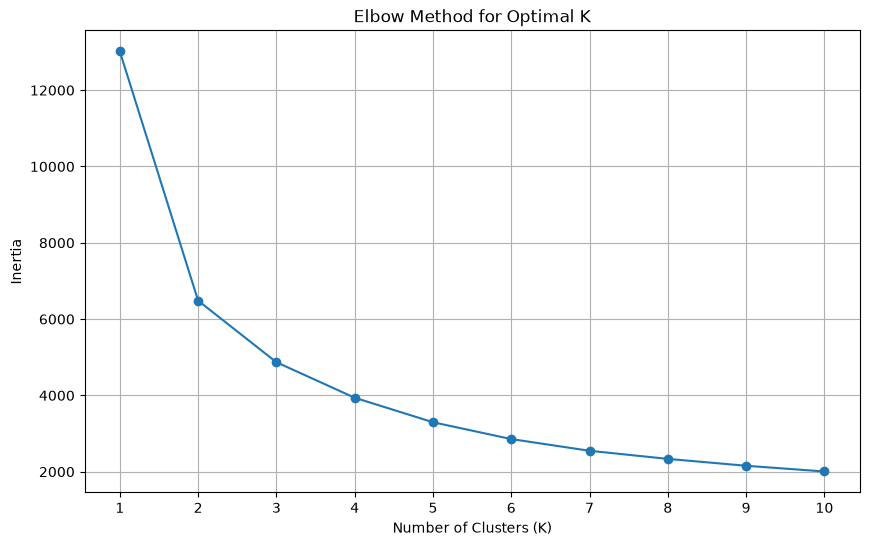

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(
    K,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K)
plt.grid(True)

plt.show()

In [35]:
from sklearn.metrics import silhouette_score

In [36]:
# Store silhouette scores
silhouette_scores = []

# Test cluster numbers from 2 to 10
K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit K-Means
    labels = kmeans.fit_predict(rfm_scaled)

    # Calculate silhouette score
    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

print("Silhouette Scores:")
print(silhouette_scores)

Silhouette Scores:
[0.4328265515350662, 0.3365174636950013, 0.33751704921261194, 0.3162001336222631, 0.3124091056438892, 0.30918598433785954, 0.30327504528060134, 0.281084500299107, 0.2766585172543556]


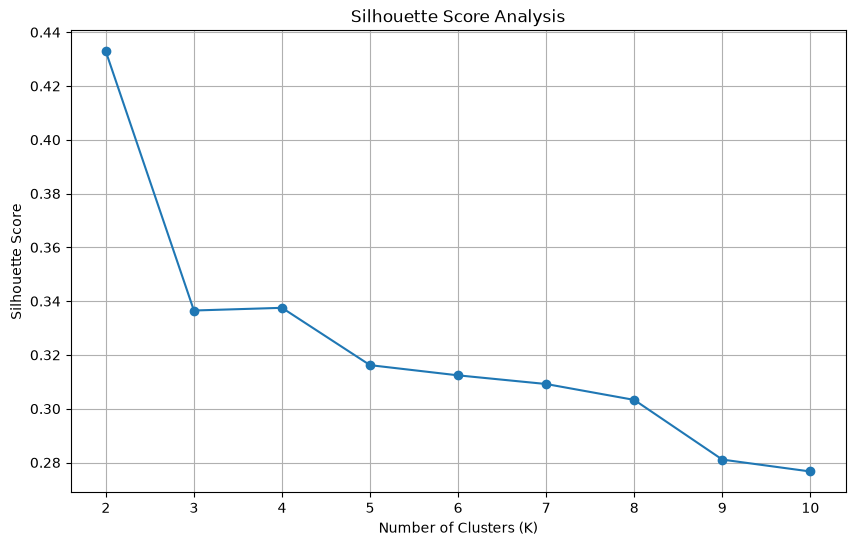

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(
    K,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")

plt.xticks(K)
plt.grid(True)

plt.show()


In [38]:
# Train the final K-Means model

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign cluster labels to customers
rfm_scaled["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

# Check the number of customers in each cluster
print("Customer distribution:")
print(rfm_scaled["Cluster"].value_counts())

Customer distribution:
Cluster
0    2672
1    1666
Name: count, dtype: int64


In [39]:
# Add cluster labels to the original RFM data

rfm["Cluster"] = rfm_scaled["Cluster"]

# Calculate average RFM values for each cluster

cluster_analysis = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
})

print("Customer Segment Analysis:")
print(cluster_analysis.round(2))

Customer Segment Analysis:
         Recency  Frequency  Monetary
Cluster                              
0         134.09       1.67    495.59
1          25.89       8.44   4539.60


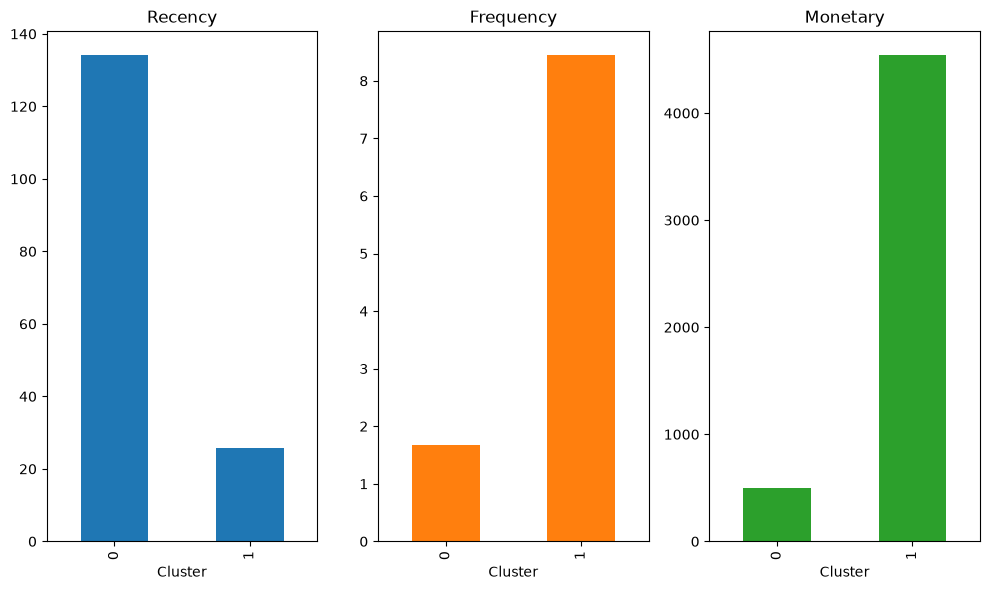

In [40]:
# Plot average RFM values for each cluster

cluster_analysis.plot(
    kind="bar",
    figsize=(10, 6),
    subplots=True,
    layout=(1, 3),
    legend=False,
    title=["Recency", "Frequency", "Monetary"]
)

plt.tight_layout()
plt.show()

In [41]:
# Calculate detailed statistics for each cluster

cluster_details = rfm.groupby("Cluster").agg({
    "Recency": ["mean", "median"],
    "Frequency": ["mean", "median"],
    "Monetary": ["mean", "median"]
})

print("Detailed Customer Segment Statistics:")
print(cluster_details.round(2))


Detailed Customer Segment Statistics:
        Recency        Frequency        Monetary         
           mean median      mean median     mean   median
Cluster                                                  
0        134.09   96.0      1.67    1.0   495.59   363.08
1         25.89   16.0      8.44    6.0  4539.60  2061.08


In [42]:

# Assign meaningful names to customer segments

segment_names = {
    0: "At-Risk / Low-Engagement Customers",
    1: "High-Value / Loyal Customers"
}

# Create a new column with customer segment names
rfm["Segment"] = rfm["Cluster"].map(segment_names)

# Check the customer distribution across segments
print("Customer Segment Distribution:")
print(rfm["Segment"].value_counts())

# Calculate the percentage of customers in each segment
print("\nCustomer Segment Percentage:")
print((rfm["Segment"].value_counts(normalize=True) * 100).round(2))


Customer Segment Distribution:
Segment
At-Risk / Low-Engagement Customers    2672
High-Value / Loyal Customers          1666
Name: count, dtype: int64

Customer Segment Percentage:
Segment
At-Risk / Low-Engagement Customers    61.6
High-Value / Loyal Customers          38.4
Name: proportion, dtype: float64


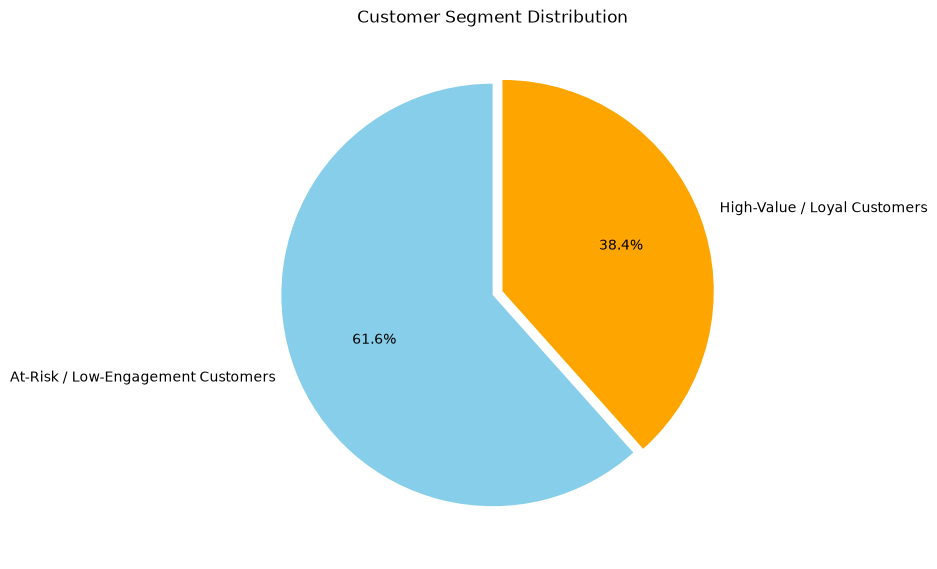

In [43]:

# Visualize customer segment distribution

plt.figure(figsize=(8, 6))

rfm["Segment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["skyblue", "orange"],
    explode=(0, 0.05)
)

plt.title("Customer Segment Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [44]:

# Calculate total revenue contribution by customer segment

segment_revenue = rfm.groupby("Segment")["Monetary"].sum()

print("Revenue Contribution by Segment:")
print(segment_revenue)

# Calculate percentage revenue contribution
revenue_percentage = (
    segment_revenue / segment_revenue.sum()
) * 100

print("\nRevenue Contribution Percentage:")
print(revenue_percentage.round(2))


Revenue Contribution by Segment:
Segment
At-Risk / Low-Engagement Customers    1324229.693
High-Value / Loyal Customers          7562979.201
Name: Monetary, dtype: float64

Revenue Contribution Percentage:
Segment
At-Risk / Low-Engagement Customers    14.9
High-Value / Loyal Customers          85.1
Name: Monetary, dtype: float64


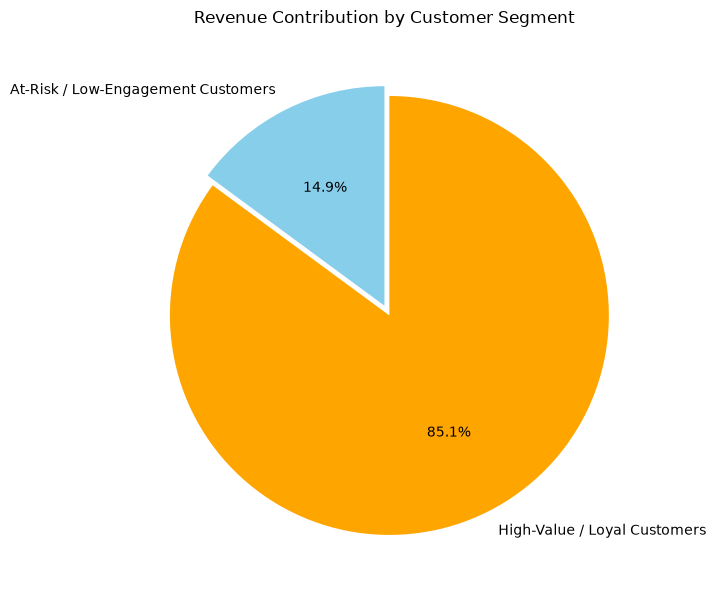

In [45]:

# Visualize revenue contribution by customer segment

plt.figure(figsize=(8, 6))

segment_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["skyblue", "orange"],
    explode=(0, 0.05)
)

plt.title("Revenue Contribution by Customer Segment")
plt.ylabel("")
plt.tight_layout()
plt.show()



In [46]:
# Calculate average revenue per customer in each segment

avg_revenue = rfm.groupby("Segment")["Monetary"].mean()

print("Average Revenue per Customer:")
print(avg_revenue.round(2))

Average Revenue per Customer:
Segment
At-Risk / Low-Engagement Customers     495.59
High-Value / Loyal Customers          4539.60
Name: Monetary, dtype: float64


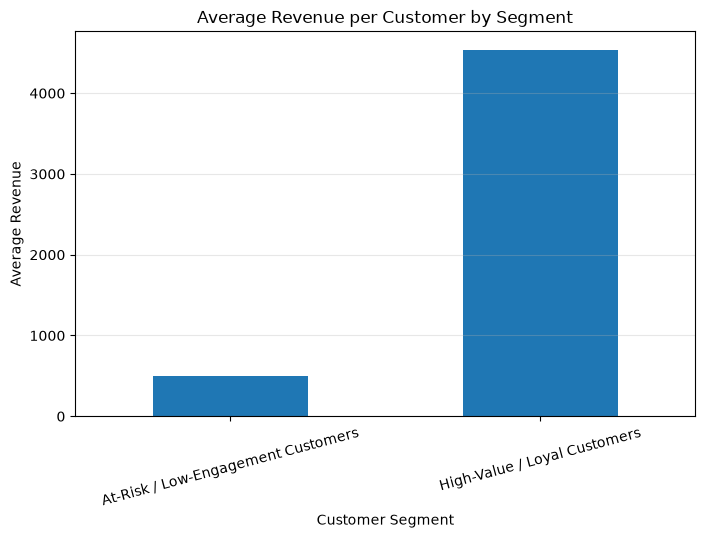

In [47]:
# Plot average revenue per customer

plt.figure(figsize=(8, 5))

avg_revenue.plot(kind="bar")

plt.title("Average Revenue per Customer by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Revenue")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [48]:
# Save customer segmentation results

rfm.to_csv(
    "../data/processed/customer_segments.csv",
    index=True
)

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


In [49]:
# Create a separate dataset for Power BI

dashboard_df = rfm.reset_index()

# Display the first five rows
dashboard_df.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,1,High-Value / Loyal Customers
1,12347.0,2,7,4310.00,1,High-Value / Loyal Customers
2,12348.0,75,4,1797.24,1,High-Value / Loyal Customers
3,12349.0,19,1,1757.55,0,At-Risk / Low-Engagement Customers
4,12350.0,310,1,334.40,0,At-Risk / Low-Engagement Customers


In [50]:
# Check dataset structure

print("Dataset shape:", dashboard_df.shape)

print("\nColumn names:")
print(dashboard_df.columns.tolist())

print("\nMissing values:")
print(dashboard_df.isnull().sum())

Dataset shape: (4338, 6)

Column names:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']

Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
Cluster       0
Segment       0
dtype: int64


In [51]:
# Check data types
print("Data Types:")
print(dashboard_df.dtypes)

# Check duplicate customer records
print("\nDuplicate CustomerIDs:")
print(dashboard_df["CustomerID"].duplicated().sum())

Data Types:
CustomerID    float64
Recency         int64
Frequency       int64
Monetary      float64
Cluster         int32
Segment           str
dtype: object

Duplicate CustomerIDs:
0


In [52]:
# Convert CustomerID to integer

dashboard_df["CustomerID"] = dashboard_df["CustomerID"].astype("int64")

# Verify the change
print(dashboard_df.dtypes)

CustomerID      int64
Recency         int64
Frequency       int64
Monetary      float64
Cluster         int32
Segment           str
dtype: object


In [53]:
# Save the cleaned dataset for Power BI

dashboard_df.to_csv(
    "../data/processed/customer_segments_powerbi.csv",
    index=False
)

print("Power BI dataset exported successfully!")

Power BI dataset exported successfully!


In [54]:
# Read the exported CSV file

powerbi_df = pd.read_csv(
    "../data/processed/customer_segments_powerbi.csv"
)

# Verify the exported dataset
print("Dataset shape:", powerbi_df.shape)
print("\nFirst 5 rows:")
display(powerbi_df.head())

print("\nMissing values:")
print(powerbi_df.isnull().sum().sum())

Dataset shape: (4338, 6)

First 5 rows:


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,1,High-Value / Loyal Customers
1,12347,2,7,4310.00,1,High-Value / Loyal Customers
2,12348,75,4,1797.24,1,High-Value / Loyal Customers
3,12349,19,1,1757.55,0,At-Risk / Low-Engagement Customers
4,12350,310,1,334.40,0,At-Risk / Low-Engagement Customers



Missing values:
0


In [55]:
# Check the variables currently available in the notebook
%whos

Variable                        Type              Data/Info
-----------------------------------------------------------
K                               range             range(2, 11)
KMeans                          ABCMeta           <class 'sklearn.cluster._kmeans.KMeans'>
StandardScaler                  type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
average_order_value             float64           479.56016047917126
avg_revenue                     Series            Shape: (2,)
axes                            ndarray           3: 3 elems, type `object`, 24 bytes
cancelled_and_negative          DataFrame         Shape: (9288, 8)
cancelled_invoices              DataFrame         Shape: (9288, 8)
cluster_analysis                DataFrame         Shape: (2, 3)
cluster_details                 DataFrame         Shape: (2, 6)
dashboard_df                    DataFrame         Shape: (4338, 6)
df                              DataFrame         Shape: (541909, 8)
df_cl

In [56]:
print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nTransaction date range:")
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())

print("\nSample records:")
display(df.head())

Dataset shape: (541909, 8)

Dataset columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Transaction date range:
2010-12-01 08:26:00
2011-12-09 12:50:00

Sample records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [57]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nTransaction date range:")
print("Start:", df_clean["InvoiceDate"].min())
print("End:", df_clean["InvoiceDate"].max())

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nSample records:")
display(df_clean.head())

Cleaned dataset shape: (392692, 10)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'YearMonth']

Transaction date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
YearMonth      0
dtype: int64

Sample records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [58]:
# Check important column data types
print("InvoiceDate data type:", df_clean["InvoiceDate"].dtype)
print("CustomerID data type:", df_clean["CustomerID"].dtype)
print("TotalPrice data type:", df_clean["TotalPrice"].dtype)

# Count unique customers and invoices
print("\nUnique customers:", df_clean["CustomerID"].nunique())
print("Unique invoices:", df_clean["InvoiceNo"].nunique())

# Check the number of unique transaction dates
print("Unique transaction dates:", df_clean["InvoiceDate"].nunique())

# Check the earliest and latest purchase dates
print("\nEarliest purchase:", df_clean["InvoiceDate"].min())
print("Latest purchase:", df_clean["InvoiceDate"].max())

InvoiceDate data type: datetime64[us]
CustomerID data type: float64
TotalPrice data type: float64

Unique customers: 4338
Unique invoices: 18532
Unique transaction dates: 17282

Earliest purchase: 2010-12-01 08:26:00
Latest purchase: 2011-12-09 12:50:00


In [59]:
import pandas as pd

# Define the snapshot date
snapshot_date = pd.Timestamp("2011-09-10")

# Define the observation period
observation_start = snapshot_date - pd.DateOffset(months=6)

# Define the 90-day prediction period
prediction_end = snapshot_date + pd.Timedelta(days=90)

print("Observation period:")
print(observation_start, "to", snapshot_date)

print("\nPrediction period:")
print(snapshot_date, "to", prediction_end)

print("\nActual dataset end:")
print(df_clean["InvoiceDate"].max())

Observation period:
2011-03-10 00:00:00 to 2011-09-10 00:00:00

Prediction period:
2011-09-10 00:00:00 to 2011-12-09 00:00:00

Actual dataset end:
2011-12-09 12:50:00


In [60]:
# Observation period: historical customer behavior
observation_data = df_clean[
    (df_clean["InvoiceDate"] >= observation_start) &
    (df_clean["InvoiceDate"] < snapshot_date)
].copy()

# Prediction period: future customer purchases
prediction_data = df_clean[
    (df_clean["InvoiceDate"] >= snapshot_date) &
    (df_clean["InvoiceDate"] < prediction_end)
].copy()

print("Observation dataset:", observation_data.shape)
print("Prediction dataset:", prediction_data.shape)

print("\nObservation date range:")
print(observation_data["InvoiceDate"].min())
print(observation_data["InvoiceDate"].max())

print("\nPrediction date range:")
print(prediction_data["InvoiceDate"].min())
print(prediction_data["InvoiceDate"].max())

Observation dataset: (159618, 10)
Prediction dataset: (158242, 10)

Observation date range:
2011-03-10 07:42:00
2011-09-09 15:53:00

Prediction date range:
2011-09-11 10:35:00
2011-12-08 20:01:00


In [61]:
# Group historical transactions by customer
customer_features = observation_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
    Total_Quantity=("Quantity", "sum")
)

# Calculate average order value
customer_features["Average_Order_Value"] = (
    customer_features["Monetary"] / customer_features["Frequency"]
)

print("Customer feature dataset shape:", customer_features.shape)

display(customer_features.head())

Customer feature dataset shape: (2810, 5)


,Recency,Frequency,Monetary,Total_Quantity,Average_Order_Value
CustomerID,,,,,
12347.0,38,3,1603.68,956,534.56
12348.0,157,1,367.00,269,367.00
12352.0,171,2,280.66,127,140.33
12353.0,113,1,89.00,20,89.00
12354.0,141,1,1079.40,530,1079.40


In [62]:
# Count unique invoices for each customer in the prediction period
future_purchases = prediction_data.groupby("CustomerID")["InvoiceNo"].nunique()

# Create churn labels
customer_features["Churn"] = (
    ~customer_features.index.isin(future_purchases.index)
).astype(int)

# Check the churn distribution
print(customer_features["Churn"].value_counts())

print("\nChurn percentages:")
print(
    customer_features["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn
0    1729
1    1081
Name: count, dtype: int64

Churn percentages:
Churn
0    61.53
1    38.47
Name: proportion, dtype: float64


In [63]:
# Compare average customer behavior by churn status
churn_profile = customer_features.groupby("Churn").agg(
    Customer_Count=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Average_Order_Value=("Average_Order_Value", "mean"),
    Average_Quantity=("Total_Quantity", "mean")
).round(2)

display(churn_profile)

,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Average_Order_Value,Average_Quantity
Churn,,,,,,
0,1729,54.92,3.70,1766.72,405.80,1053.33
1,1081,83.97,1.63,590.75,363.67,334.19


In [64]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = customer_features.drop(columns=["Churn"])
y = customer_features["Churn"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the resulting dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (2248, 5)
Testing features: (562, 5)

Training target distribution:
Churn
0    1383
1     865
Name: count, dtype: int64

Testing target distribution:
Churn
0    346
1    216
Name: count, dtype: int64


In [65]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create a machine learning pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [66]:
# Predict churn for unseen test customers
y_pred = logistic_model.predict(X_test)

# Predict churn probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.head(10).values)

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob[:10].round(3))

First 10 actual labels:
[1 1 1 0 1 0 1 0 0 0]

First 10 predicted labels:
[0 1 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0.286 0.555 0.442 0.453 0.297 0.396 0.217 0.    0.499 0.328]


In [67]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))

Accuracy: 0.6584

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74       346
           1       0.57      0.45      0.51       216

    accuracy                           0.66       562
   macro avg       0.63      0.62      0.62       562
weighted avg       0.65      0.66      0.65       562


Confusion Matrix:
[[272  74]
 [118  98]]

ROC-AUC Score: 0.7052


In [68]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Learn scaling parameters from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling parameters to test data
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (2248, 5)
Scaled testing data shape: (562, 5)


In [69]:
# Initialize a new Logistic Regression model
logistic_model_scaled = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Train using scaled training features
logistic_model_scaled.fit(X_train_scaled, y_train)

print("Scaled Logistic Regression model trained successfully!")

Scaled Logistic Regression model trained successfully!


In [70]:
# Predict churn labels
y_pred_scaled = logistic_model_scaled.predict(X_test_scaled)

# Predict probability of churn
y_prob_scaled = logistic_model_scaled.predict_proba(X_test_scaled)[:, 1]

print("First 10 predicted labels:")
print(y_pred_scaled[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_scaled[:10].round(3))

First 10 predicted labels:
[0 1 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0.286 0.555 0.442 0.453 0.297 0.396 0.217 0.    0.499 0.328]


In [71]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Scaled Model Evaluation")

print("\nAccuracy:")
print(round(accuracy_score(y_test, y_pred_scaled), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_scaled))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_scaled))

print("\nROC-AUC Score:")
print(round(roc_auc_score(y_test, y_prob_scaled), 4))

Scaled Model Evaluation

Accuracy:
0.6584

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74       346
           1       0.57      0.45      0.51       216

    accuracy                           0.66       562
   macro avg       0.63      0.62      0.62       562
weighted avg       0.65      0.66      0.65       562


Confusion Matrix:
[[272  74]
 [118  98]]

ROC-AUC Score:
0.7052


In [72]:
from sklearn.metrics import classification_report, confusion_matrix

# Use a lower threshold to identify more potential churn customers
threshold = 0.40

y_pred_threshold = (y_prob_scaled >= threshold).astype(int)

print("Classification Report (Threshold = 0.40):")
print(classification_report(y_test, y_pred_threshold))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_threshold))


Classification Report (Threshold = 0.40):
              precision    recall  f1-score   support

           0       0.77      0.61      0.68       346
           1       0.53      0.70      0.61       216

    accuracy                           0.65       562
   macro avg       0.65      0.66      0.64       562
weighted avg       0.68      0.65      0.65       562


Confusion Matrix:
[[212 134]
 [ 64 152]]


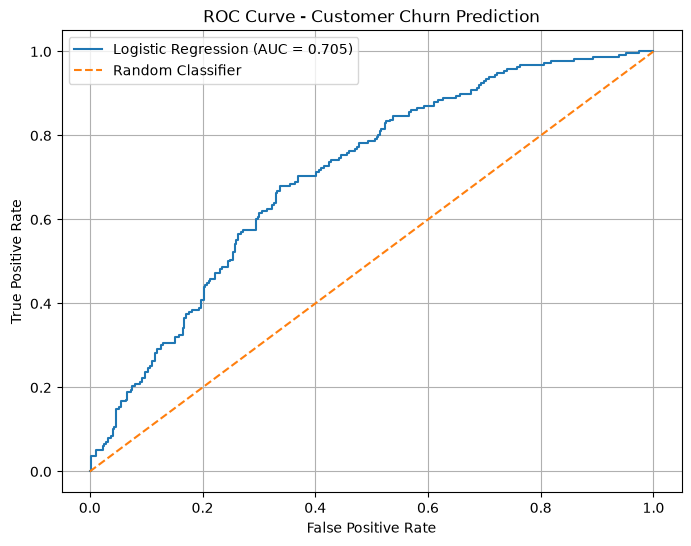

In [73]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_scaled)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_scaled):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid()
plt.show()

In [74]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model using the training data
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [75]:
# Predict churn labels for test customers
y_pred_rf = rf_model.predict(X_test)

# Predict churn probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predicted labels:")
print(y_pred_rf[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_rf[:10].round(3))

First 10 predicted labels:
[1 1 0 1 0 0 0 0 1 0]

First 10 churn probabilities:
[0.795 0.685 0.39  0.565 0.32  0.36  0.11  0.01  0.6   0.25 ]


In [76]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Random Forest Evaluation")

# Calculate accuracy
print("\nAccuracy:")
print(round(accuracy_score(y_test, y_pred_rf), 4))

# Generate classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Generate confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# Calculate ROC-AUC
print("\nROC-AUC Score:")
print(round(roc_auc_score(y_test, y_prob_rf), 4))


Random Forest Evaluation

Accuracy:
0.6317

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.70      0.70       346
           1       0.52      0.53      0.52       216

    accuracy                           0.63       562
   macro avg       0.61      0.61      0.61       562
weighted avg       0.63      0.63      0.63       562


Confusion Matrix:
[[241 105]
 [102 114]]

ROC-AUC Score:
0.6707


In [77]:
# Extract feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)


,Feature,Importance
2,Monetary,0.261220
3,Total_Quantity,0.243146
0,Recency,0.208794
4,Average_Order_Value,0.201882
1,Frequency,0.084958


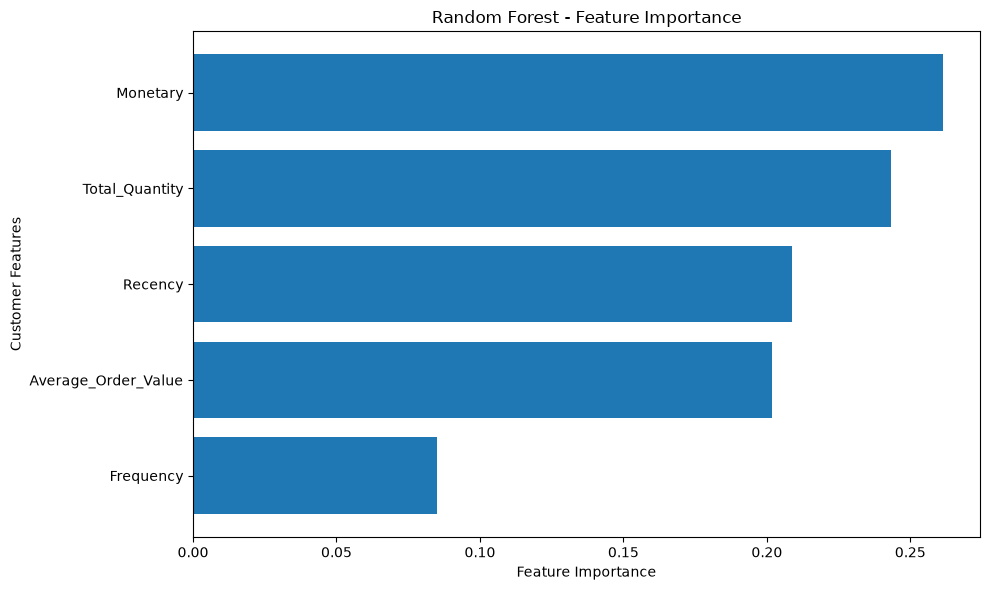

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Customer Features")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [79]:
# Use the same probability threshold as Logistic Regression
threshold = 0.40

# Convert churn probabilities into predicted labels
y_pred_rf_threshold = (y_prob_rf >= threshold).astype(int)

# Evaluate the Random Forest model
print("Random Forest Evaluation (Threshold = 0.40):")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_threshold))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_threshold))

Random Forest Evaluation (Threshold = 0.40):

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.57      0.65       346
           1       0.51      0.71      0.59       216

    accuracy                           0.62       562
   macro avg       0.63      0.64      0.62       562
weighted avg       0.66      0.62      0.63       562


Confusion Matrix:
[[197 149]
 [ 63 153]]


In [80]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Compare both models on the same test data
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_threshold),
        accuracy_score(y_test, y_pred_rf_threshold)
    ],
    "Churn Precision": [
        precision_score(y_test, y_pred_threshold),
        precision_score(y_test, y_pred_rf_threshold)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred_threshold),
        recall_score(y_test, y_pred_rf_threshold)
    ],
    "Churn F1-Score": [
        f1_score(y_test, y_pred_threshold),
        f1_score(y_test, y_pred_rf_threshold)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_scaled),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

display(model_comparison.round(4))

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-Score,ROC-AUC
0,Logistic Regression,0.6477,0.5315,0.7037,0.6056,0.7052
1,Random Forest,0.6228,0.5066,0.7083,0.5907,0.6707


In [81]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression with balanced class weights
logistic_model_balanced = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

# Train using the scaled training data
logistic_model_balanced.fit(X_train_scaled, y_train)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [82]:
# Predict churn probabilities using the balanced model
y_prob_balanced = logistic_model_balanced.predict_proba(X_test_scaled)[:, 1]

# Apply the same 0.40 threshold
threshold = 0.40
y_pred_balanced = (y_prob_balanced >= threshold).astype(int)

print("First 10 predicted labels:")
print(y_pred_balanced[:10])

print("\nFirst 10 churn probabilities:")
print(y_prob_balanced[:10].round(3))

First 10 predicted labels:
[0 1 1 1 1 1 0 0 1 1]

First 10 churn probabilities:
[0.388 0.664 0.558 0.566 0.402 0.512 0.309 0.    0.612 0.439]


In [83]:
print("Balanced Logistic Regression Evaluation (Threshold = 0.40)")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

print("\nROC-AUC Score:")
print(round(roc_auc_score(y_test, y_prob_balanced), 4))

Balanced Logistic Regression Evaluation (Threshold = 0.40)

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.40      0.54       346
           1       0.48      0.87      0.62       216

    accuracy                           0.58       562
   macro avg       0.65      0.64      0.58       562
weighted avg       0.70      0.58      0.57       562


Confusion Matrix:
[[139 207]
 [ 28 188]]

ROC-AUC Score:
0.705


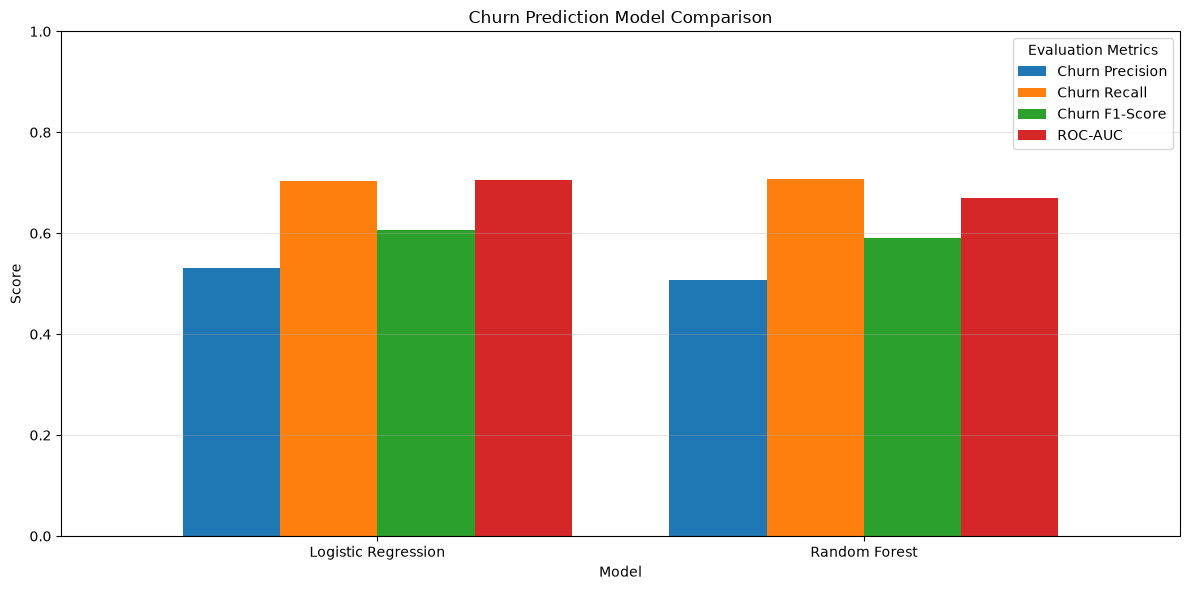

In [84]:
import matplotlib.pyplot as plt

# Select the metrics we want to compare
metrics = [
    "Churn Precision",
    "Churn Recall",
    "Churn F1-Score",
    "ROC-AUC"
]

# Create a comparison chart
comparison_plot = model_comparison.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Churn Prediction Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Compare all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_threshold),
        accuracy_score(y_test, y_pred_rf_threshold),
        accuracy_score(y_test, y_pred_balanced)
    ],
    "Churn Precision": [
        precision_score(y_test, y_pred_threshold),
        precision_score(y_test, y_pred_rf_threshold),
        precision_score(y_test, y_pred_balanced)
    ],
    "Churn Recall": [
        recall_score(y_test, y_pred_threshold),
        recall_score(y_test, y_pred_rf_threshold),
        recall_score(y_test, y_pred_balanced)
    ],
    "Churn F1-Score": [
        f1_score(y_test, y_pred_threshold),
        f1_score(y_test, y_pred_rf_threshold),
        f1_score(y_test, y_pred_balanced)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_scaled),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_balanced)
    ]
})

display(model_comparison.round(4))


,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-Score,ROC-AUC
0,Logistic Regression,0.6477,0.5315,0.7037,0.6056,0.7052
1,Random Forest,0.6228,0.5066,0.7083,0.5907,0.6707
2,Balanced Logistic Regression,0.5819,0.4759,0.8704,0.6154,0.7050


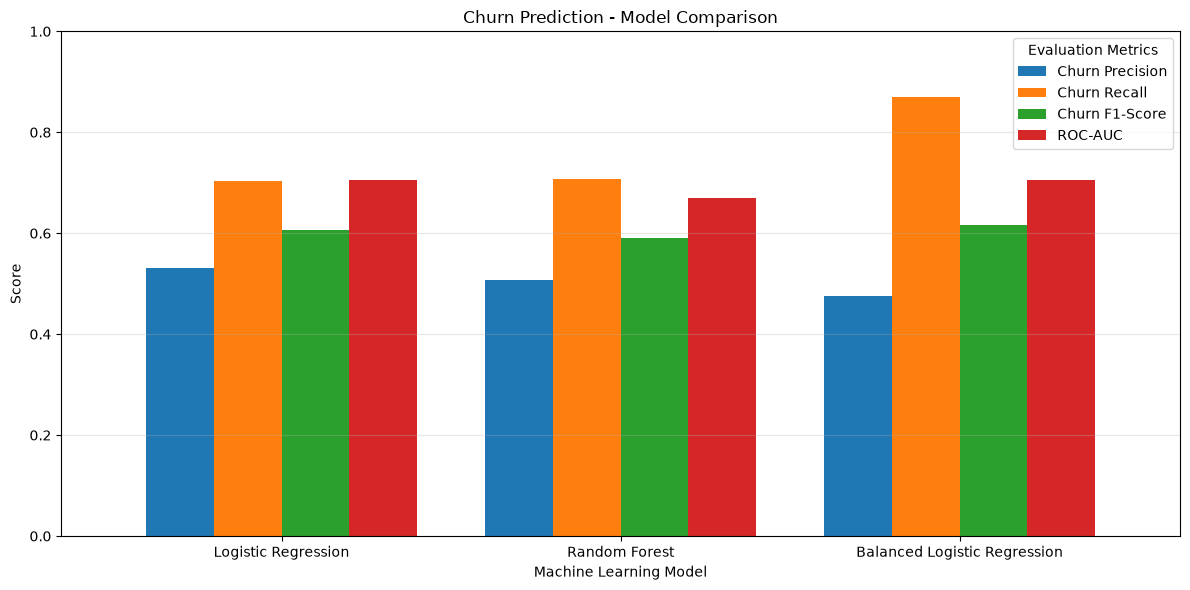

In [86]:
import matplotlib.pyplot as plt

# Metrics to compare
metrics = [
    "Churn Precision",
    "Churn Recall",
    "Churn F1-Score",
    "ROC-AUC"
]

# Prepare comparison data
plot_data = model_comparison.set_index("Model")[metrics]

# Create grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Churn Prediction - Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [87]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Thresholds we want to evaluate
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into churn predictions
    y_pred_temp = (y_prob_balanced >= threshold).astype(int)

    # Calculate evaluation metrics
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_temp, zero_division=0),
        "Recall": recall_score(y_test, y_pred_temp, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred_temp, zero_division=0)
    })

# Display results
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.2,0.4277,0.9722,0.5941
1,0.3,0.4501,0.9398,0.6087
2,0.4,0.4759,0.8704,0.6154
3,0.5,0.5216,0.7269,0.6074
4,0.6,0.5550,0.4907,0.5209
5,0.7,0.6400,0.1481,0.2406


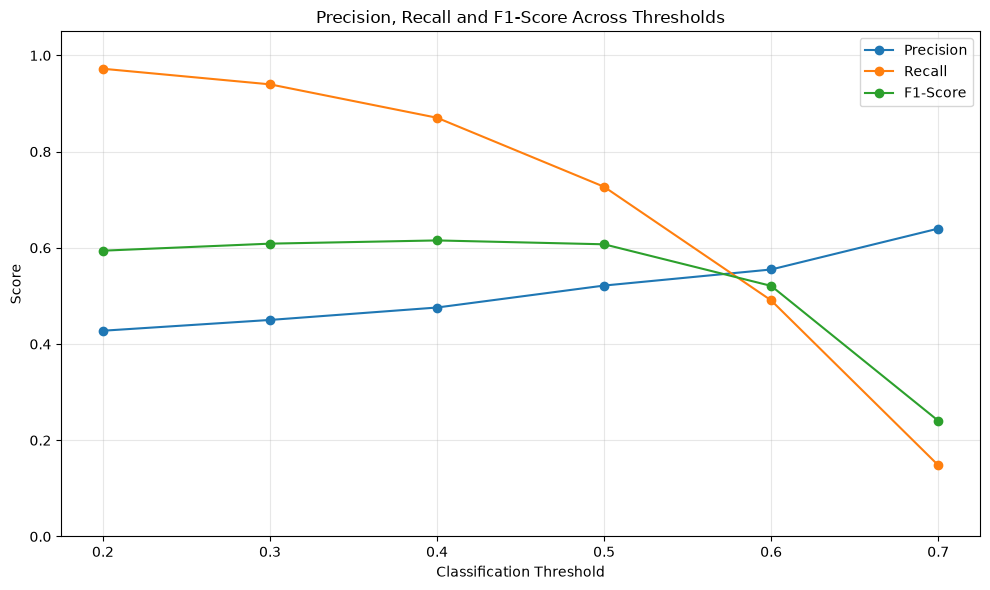

In [88]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.title("Precision, Recall and F1-Score Across Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [89]:
from sklearn.metrics import classification_report, confusion_matrix

# Final prediction using the selected threshold
final_threshold = 0.40

y_pred_final = (
    logistic_model_balanced.predict_proba(X_test_scaled)[:, 1]
    >= final_threshold
).astype(int)

# Final evaluation
print("Final Balanced Logistic Regression Evaluation")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final Balanced Logistic Regression Evaluation

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.40      0.54       346
           1       0.48      0.87      0.62       216

    accuracy                           0.58       562
   macro avg       0.65      0.64      0.58       562
weighted avg       0.70      0.58      0.57       562


Confusion Matrix:
[[139 207]
 [ 28 188]]


In [90]:
# Find the scaler and trained model variables
[
    (name, type(obj).__name__)
    for name, obj in list(globals().items())
    if "scal" in name.lower() or "model" in name.lower()
]

[('StandardScaler', 'type'),
 ('scaler', 'StandardScaler'),
 ('rfm_scaled_array', 'ndarray'),
 ('rfm_scaled', 'DataFrame'),
 ('logistic_model', 'Pipeline'),
 ('X_train_scaled', 'ndarray'),
 ('X_test_scaled', 'ndarray'),
 ('logistic_model_scaled', 'LogisticRegression'),
 ('y_pred_scaled', 'ndarray'),
 ('y_prob_scaled', 'ndarray'),
 ('rf_model', 'RandomForestClassifier'),
 ('model_comparison', 'DataFrame'),
 ('logistic_model_balanced', 'LogisticRegression')]

In [91]:
import joblib
from pathlib import Path

# Create a folder to store the trained model
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Package everything needed for future predictions
model_artifacts = {
    "model": logistic_model_balanced,
    "scaler": scaler,
    "threshold": 0.40,
    "features": list(X_train.columns)
}

# Save the artifacts
model_path = model_dir / "customer_churn_model.joblib"
joblib.dump(model_artifacts, model_path)

print(f"Model saved successfully at: {model_path.resolve()}")

Model saved successfully at: C:\Users\vaiba\OneDrive\Desktop\Projects\customer-intelligence-platform\notebooks\models\customer_churn_model.joblib


In [92]:
import joblib

# Load the saved model
loaded_artifacts = joblib.load(model_path)

# Extract the saved components
loaded_model = loaded_artifacts["model"]
loaded_scaler = loaded_artifacts["scaler"]
loaded_threshold = loaded_artifacts["threshold"]
loaded_features = loaded_artifacts["features"]

print("Model loaded successfully!")
print("Model:", type(loaded_model).__name__)
print("Scaler:", type(loaded_scaler).__name__)
print("Threshold:", loaded_threshold)
print("Features:", loaded_features)

Model loaded successfully!
Model: LogisticRegression
Scaler: StandardScaler
Threshold: 0.4
Features: ['Recency', 'Frequency', 'Monetary', 'Total_Quantity', 'Average_Order_Value']


In [93]:
import pandas as pd

# Create sample customer data using the exact feature order
sample_customer = pd.DataFrame([{
    "Recency": 25,
    "Frequency": 8,
    "Monetary": 4500,
    "Total_Quantity": 120,
    "Average_Order_Value": 562.5
}])

# Scale the customer data
sample_scaled = loaded_scaler.transform(sample_customer[loaded_features])

# Predict churn probability
churn_probability = loaded_model.predict_proba(sample_scaled)[0, 1]

# Apply our selected threshold
churn_prediction = int(churn_probability >= loaded_threshold)

print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Churn Prediction:", "Likely to Churn" if churn_prediction == 1 else "Unlikely to Churn")

Churn Probability: 4.58 %
Churn Prediction: Unlikely to Churn


In [94]:
# Inspect the existing customer-level dataset

print("Dataset shape:", customer_features.shape)

print("\nAvailable columns:")
print(customer_features.columns.tolist())

print("\nSample customer records:")
display(customer_features.head())

Dataset shape: (2810, 6)

Available columns:
['Recency', 'Frequency', 'Monetary', 'Total_Quantity', 'Average_Order_Value', 'Churn']

Sample customer records:


,Recency,Frequency,Monetary,Total_Quantity,Average_Order_Value,Churn
CustomerID,,,,,,
12347.0,38,3,1603.68,956,534.56,0
12348.0,157,1,367.00,269,367.00,0
12352.0,171,2,280.66,127,140.33,0
12353.0,113,1,89.00,20,89.00,1
12354.0,141,1,1079.40,530,1079.40,1


In [95]:
    # Calculate historical customer value statistics

customer_value = customer_features.copy()

print("Historical Customer Value Analysis")
print("----------------------------------")

print("Total customers:", len(customer_value))

print(
    "Total revenue: £",
    round(customer_value["Monetary"].sum(), 2)
)

print(
    "Average customer spending: £",
    round(customer_value["Monetary"].mean(), 2)
)

print(
    "Median customer spending: £",
    round(customer_value["Monetary"].median(), 2)
)

print(
    "Highest customer spending: £",
    round(customer_value["Monetary"].max(), 2)
)

Historical Customer Value Analysis
----------------------------------
Total customers: 2810
Total revenue: £ 3693257.35
Average customer spending: £ 1314.33
Median customer spending: £ 508.98
Highest customer spending: £ 120436.6


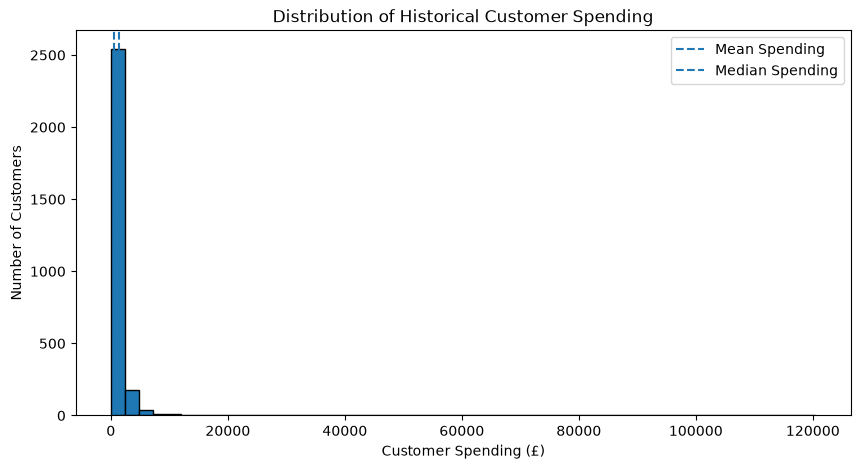

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    customer_value["Monetary"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    customer_value["Monetary"].mean(),
    linestyle="--",
    label="Mean Spending"
)

plt.axvline(
    customer_value["Monetary"].median(),
    linestyle="--",
    label="Median Spending"
)

plt.title("Distribution of Historical Customer Spending")
plt.xlabel("Customer Spending (£)")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

In [104]:
# Calculate annualized customer spending using the actual observation period

observation_months = observation_days / 30.44

customer_value["Monthly_Spending"] = (
    customer_value["Monetary"] / observation_months
)

customer_value["Annualized_Value"] = (
    customer_value["Monthly_Spending"] * 12
)

print("Observation period:", round(observation_months, 2), "months")

print(
    "Average annualized customer value: £",
    round(customer_value["Annualized_Value"].mean(), 2)
)

print(
    "Median annualized customer value: £",
    round(customer_value["Annualized_Value"].median(), 2)
)

Observation period: 12.25 months
Average annualized customer value: £ 1287.12
Median annualized customer value: £ 498.45


In [98]:
# Project customer lifetime value under different lifespan assumptions

customer_value["CLV_1_Year"] = (
    customer_value["Annualized_Value"] * 1
)

customer_value["CLV_2_Years"] = (
    customer_value["Annualized_Value"] * 2
)

customer_value["CLV_3_Years"] = (
    customer_value["Annualized_Value"] * 3
)

# Compare the projected CLV scenarios

print("Projected Customer Lifetime Value")
print("---------------------------------")

clv_summary = customer_value[
    ["CLV_1_Year", "CLV_2_Years", "CLV_3_Years"]
].agg(["mean", "median", "max"])

display(clv_summary.round(2))

Projected Customer Lifetime Value
---------------------------------


,CLV_1_Year,CLV_2_Years,CLV_3_Years
mean,2628.65,5257.31,7885.96
median,1017.96,2035.92,3053.88
max,240873.20,481746.40,722619.60


In [99]:
# Segment customers based on annualized value

customer_value["Value_Segment"] = pd.qcut(
    customer_value["Annualized_Value"],
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Premium Value"
    ]
)

# Summarize each customer value segment

value_segment_summary = customer_value.groupby(
    "Value_Segment",
    observed=False
).agg(
    Customer_Count=("Monetary", "count"),
    Average_Annual_Value=("Annualized_Value", "mean"),
    Median_Annual_Value=("Annualized_Value", "median"),
    Total_Historical_Revenue=("Monetary", "sum")
).round(2)

display(value_segment_summary)

,Customer_Count,Average_Annual_Value,Median_Annual_Value,Total_Historical_Revenue
Value_Segment,,,,
Low Value,703,303.04,303.96,106517.10
Medium Value,702,728.05,698.80,255546.60
High Value,702,1543.98,1499.50,541935.66
Premium Value,703,7935.30,4061.96,2789257.99


In [100]:
# Analyze churn across customer value segments

value_churn_summary = customer_value.groupby(
    "Value_Segment",
    observed=False
).agg(
    Customer_Count=("Churn", "count"),
    Churned_Customers=("Churn", "sum"),
    Churn_Rate=("Churn", "mean"),
    Average_Annual_Value=("Annualized_Value", "mean"),
    Historical_Revenue=("Monetary", "sum")
)

# Convert churn rate into percentage

value_churn_summary["Churn_Rate"] = (
    value_churn_summary["Churn_Rate"] * 100
)

display(value_churn_summary.round(2))

,Customer_Count,Churned_Customers,Churn_Rate,Average_Annual_Value,Historical_Revenue
Value_Segment,,,,,
Low Value,703,407,57.89,303.04,106517.10
Medium Value,702,329,46.87,728.05,255546.60
High Value,702,242,34.47,1543.98,541935.66
Premium Value,703,103,14.65,7935.30,2789257.99


In [101]:
# Analyze historical revenue by churn status and value segment

churn_revenue_summary = customer_value.groupby(
    ["Value_Segment", "Churn"],
    observed=False
).agg(
    Customer_Count=("Monetary", "count"),
    Historical_Revenue=("Monetary", "sum"),
    Average_Customer_Value=("Monetary", "mean")
).round(2)

display(churn_revenue_summary)

Customer_Count  Historical_Revenue  \
Value_Segment Churn                                       
Low Value     0                 296            47179.00   
              1                 407            59338.10   
Medium Value  0                 373           137380.27   
              1                 329           118166.33   
High Value    0                 460           361660.12   
              1                 242           180275.54   
Premium Value 0                 600          2508441.28   
              1                 103           280816.71   

                     Average_Customer_Value  
Value_Segment Churn                          
Low Value     0                      159.39  
              1                      145.79  
Medium Value  0                      368.31  
              1                      359.17  
High Value    0                      786.22  
              1                      744.94  
Premium Value 0                     4180.74  
              1                     2726.38

In [102]:
# Create a retention priority summary

retention_priority = customer_value[
    customer_value["Churn"] == 1
].groupby(
    "Value_Segment",
    observed=False
).agg(
    At_Risk_Customers=("Churn", "count"),
    Historical_Revenue=("Monetary", "sum"),
    Average_Customer_Value=("Monetary", "mean"),
    Average_Annualized_Value=("Annualized_Value", "mean")
).sort_values(
    by="Historical_Revenue",
    ascending=False
)

display(retention_priority.round(2))

,At_Risk_Customers,Historical_Revenue,Average_Customer_Value,Average_Annualized_Value
Value_Segment,,,,
Premium Value,103,280816.71,2726.38,5452.75
High Value,242,180275.54,744.94,1489.88
Medium Value,329,118166.33,359.17,718.34
Low Value,407,59338.10,145.79,291.59


## Business Recommendations and Retention Strategy

Based on the customer segmentation, churn analysis, and customer lifetime value estimation, the following strategies are recommended:

### 1. Premium Value Customers
- Prioritize personalized retention campaigns.
- Provide loyalty rewards, exclusive offers, and early access to products.
- Monitor purchasing activity to identify changes in customer behavior.

### 2. High Value Customers
- Encourage repeat purchases through loyalty programs.
- Provide personalized product recommendations.
- Identify customers whose purchase frequency is declining.

### 3. Medium Value Customers
- Use targeted promotions to encourage more frequent purchases.
- Recommend complementary products based on previous purchases.
- Monitor changes in purchasing behavior.

### 4. Low Value Customers
- Use cost-effective email campaigns and automated engagement.
- Test limited-time discounts to encourage repeat purchases.
- Avoid spending disproportionately on expensive retention incentives.

### Overall Business Conclusion

The analysis demonstrates that customer value and churn behavior are important factors in developing an effective retention strategy. Premium Value customers contribute disproportionately to historical revenue, making their retention particularly important.

The business should prioritize customers based on both their estimated churn risk and their financial contribution rather than relying on churn probability alone.

In [103]:
print("First transaction date:", df["InvoiceDate"].min())
print("Last transaction date:", df["InvoiceDate"].max())

observation_days = (
    df["InvoiceDate"].max() - df["InvoiceDate"].min()
).days

print("Observation period:", observation_days, "days")
print("Observation period in months:", round(observation_days / 30.44, 2))

First transaction date: 2010-12-01 08:26:00
Last transaction date: 2011-12-09 12:50:00
Observation period: 373 days
Observation period in months: 12.25


In [105]:
# Calculate monthly and annualized customer spending
observation_months = observation_days / 30.44

customer_value["Monthly_Spending"] = (
    customer_value["Monetary"] / observation_months
)

customer_value["Annualized_Value"] = (
    customer_value["Monthly_Spending"] * 12
)

In [106]:
# Final Business Recommendations

print("CUSTOMER RETENTION AND BUSINESS RECOMMENDATIONS")
print("=" * 55)

# 1. Identify the customer segment with the highest churn rate
highest_churn_segment = value_churn_summary["Churn_Rate"].idxmax()
highest_churn_rate = value_churn_summary.loc[
    highest_churn_segment, "Churn_Rate"
]

print("\n1. Highest Churn Risk")
print(
    f"{highest_churn_segment} has the highest churn rate "
    f"at {highest_churn_rate:.2f}%."
)

# 2. Identify the segment contributing the most historical revenue
highest_revenue_segment = value_segment_summary[
    "Total_Historical_Revenue"
].idxmax()

print("\n2. Revenue Contribution")
print(
    f"{highest_revenue_segment} contributes the highest "
    "historical revenue."
)

# 3. Identify the highest-value segment
highest_clv_segment = value_segment_summary[
    "Average_Annual_Value"
].idxmax()

print("\n3. Customer Lifetime Value")
print(
    f"{highest_clv_segment} customers have the highest "
    "average annualized customer value."
)

# 4. Business recommendations
print("\n4. Recommended Business Actions")

print(
    "- Premium Value: Focus on loyalty rewards, personalized "
    "experiences, and exclusive offers."
)

print(
    "- High Value: Encourage repeat purchases through targeted "
    "promotions and early access."
)

print(
    "- Medium Value: Use personalized recommendations and "
    "purchase incentives to increase engagement."
)

print(
    "- Low Value: Use cost-effective re-engagement campaigns "
    "rather than expensive retention offers."
)

print(
    "- At-risk customers: Prioritize customers with high "
    "annualized value when planning retention campaigns."
)

print("\n" + "=" * 55)
print("End of Business Recommendations")

CUSTOMER RETENTION AND BUSINESS RECOMMENDATIONS

1. Highest Churn Risk
Low Value has the highest churn rate at 57.89%.

2. Revenue Contribution
Premium Value contributes the highest historical revenue.

3. Customer Lifetime Value
Premium Value customers have the highest average annualized customer value.

4. Recommended Business Actions
- Premium Value: Focus on loyalty rewards, personalized experiences, and exclusive offers.
- High Value: Encourage repeat purchases through targeted promotions and early access.
- Medium Value: Use personalized recommendations and purchase incentives to increase engagement.
- Low Value: Use cost-effective re-engagement campaigns rather than expensive retention offers.
- At-risk customers: Prioritize customers with high annualized value when planning retention campaigns.

End of Business Recommendations
